In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv('placement.csv')
df.head()

,Unnamed: 0,cgpa,iq,placement
0,0,6.8,123.0,1
1,1,5.9,106.0,0
2,2,5.3,121.0,0
3,3,7.4,132.0,1
4,4,5.8,142.0,0


In [4]:
df.shape

(100, 4)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  100 non-null    int64  
 1   cgpa        100 non-null    float64
 2   iq          100 non-null    float64
 3   placement   100 non-null    int64  
dtypes: float64(2), int64(2)
memory usage: 3.3 KB


In [6]:
df = df.iloc[:,1:]
df.head()

,cgpa,iq,placement
0,6.8,123.0,1
1,5.9,106.0,0
2,5.3,121.0,0
3,7.4,132.0,1
4,5.8,142.0,0


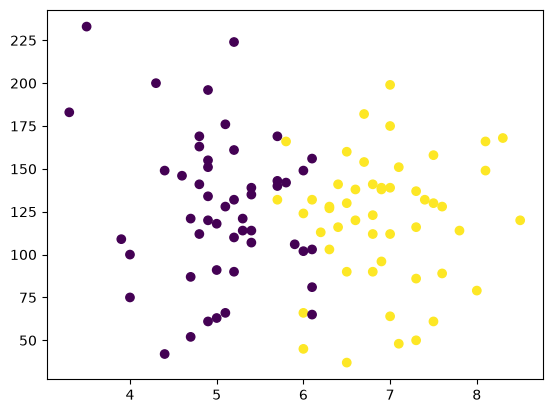

In [8]:
import matplotlib.pyplot as plt
plt.scatter(df['cgpa'],df['iq'], c=df['placement'])

In [10]:
X = df.iloc[:,0:2]
y = df.iloc[:, -1]

In [11]:
X

,cgpa,iq
0,6.8,123.0
1,5.9,106.0
2,5.3,121.0
3,7.4,132.0
4,5.8,142.0
...,...,...
95,4.3,200.0
96,4.4,42.0
97,6.7,182.0
98,6.3,103.0


In [13]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.1)

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)

In [17]:
X_train

array([[-1.40385165, -2.02516283],
       [-0.54023819, -0.41570725],
       [ 0.06429122, -1.45566316],
       [-1.14476761, -0.06905527],
       [-1.05840627, -0.29190297],
       [-1.05840627,  0.97090064],
       [-1.83565837, -0.36618554],
       [ 0.4097366 ,  0.89661808],
       [-0.10843147, -0.4404681 ],
       [-0.97204492,  0.67377038],
       [-0.02207012, -1.95088027],
       [ 0.92790468, -1.8765977 ],
       [ 0.23701391,  0.10427071],
       [ 0.66882064,  0.42616183],
       [-0.02207012, -1.43090231],
       [-0.71296088, -0.83664178],
       [ 0.84154333, -0.29190297],
       [ 1.10062737, -1.82707599],
       [ 0.5824593 ,  0.74805295],
       [ 1.96424082,  1.09470492],
       [-0.02207012,  0.00522729],
       [ 1.27335006,  0.15379242],
       [ 1.27335006, -1.55470658],
       [ 0.32337526, -0.19285955],
       [ 0.15065257, -0.26714211],
       [ 2.13696351, -0.09381613],
       [ 0.66882064, -0.29190297],
       [ 1.10062737,  0.32711841],
       [-0.88568357,

In [18]:
X_test = scaler.transform(X_test)

In [19]:
X_test

array([[-1.40385165,  0.62424867],
       [-0.54023819,  0.2775967 ],
       [-1.14476761, -1.77755428],
       [ 1.10062737, -0.9356852 ],
       [-0.02207012, -0.53951152],
       [-0.79932223,  1.29279176],
       [-0.62659954, -0.24238126],
       [-0.54023819,  0.37664012],
       [ 0.32337526,  0.42616183],
       [ 0.66882064, -0.01953356]])

In [20]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [23]:
y_pred=model.predict(X_test)

In [22]:
y_test

88    0
49    0
94    0
90    1
62    0
15    0
46    0
12    0
54    1
0     1
Name: placement, dtype: int64

In [24]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test,y_pred)

0.9

In [27]:
!pip install mlxtend

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   --------------- ------------------------ 0.5/1.4 MB 1.7 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 1.1 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 1.1 MB/s eta 0:00:01
   ----------------------- ---------------- 0.8/1.4 MB 1.1 MB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 674.0 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 674.0 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 674.0 kB/s eta 0:00:01
   ------------------------------ --------- 1.0/1.4 MB 674.0 kB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 545.1 kB/s  0:00:02



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


<Axes: >

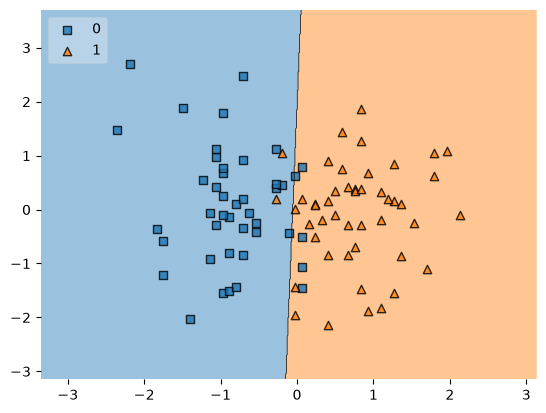

In [28]:
from mlxtend.plotting import plot_decision_regions
# Plotting decision regions
plot_decision_regions(X_train, y_train.values, clf=model, legend=2)


In [29]:
# save the model
import joblib
joblib.dump(model, 'days100_of_ml.joblib')

['days100_of_ml.joblib']

In [30]:
model = joblib.load('days100_of_ml.joblib')